<a href="https://colab.research.google.com/github/Ana-Beatriz-N/ProcessamentoDeImagens/blob/main/2BimestrePortifolio2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [2]:
def implot(imgs, titulos, cmap='gray', tamanho=6):
  amount = len(imgs)

  plt.figure(figsize=(tamanho * amount, tamanho))
  for i in range(amount):
    plt.subplot(1, amount, i+1)
    plt.imshow(imgs[i], cmap=cmap)
    plt.title(titulos[i])
    plt.axis('off')

  plt.show()

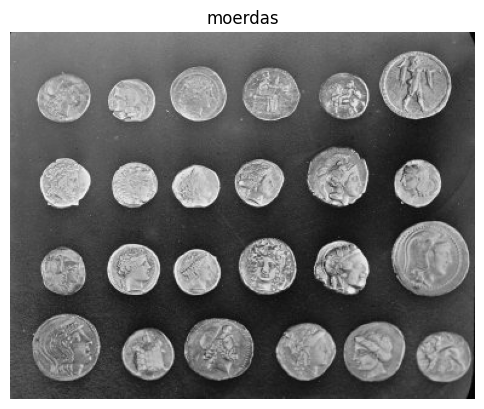

In [3]:
moedas = data.coins()
implot([moedas], ['moerdas'])

In [4]:
def comparar_segmentacoes(imagem, nome, area_minima=500, bloco=101, constante=-10):
    cinza = cv2.cvtColor(imagem, cv2.COLOR_RGB2GRAY) if imagem.ndim == 3 else imagem.copy()
    suave = cv2.GaussianBlur(cinza, (5, 5), 0)
    mascara = cv2.adaptiveThreshold(suave, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                    cv2.THRESH_BINARY, bloco, constante)

    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL,
                                   cv2.CHAIN_APPROX_SIMPLE)
    contornos = [c for c in contornos if cv2.contourArea(c) > area_minima]

    semantica = np.zeros_like(cinza, dtype=np.uint8)
    instancias = np.zeros((*cinza.shape, 3), dtype=np.uint8)
    cores = plt.get_cmap('hsv')(np.linspace(0, 1, len(contornos), endpoint=False))[:, :3]

    for i, contorno in enumerate(contornos):
        cv2.drawContours(semantica, [contorno], -1, 255, -1)
        cor = tuple(int(v * 255) for v in cores[i])
        cv2.drawContours(instancias, [contorno], -1, cor, -1)

    fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
    eixos[0].imshow(imagem, cmap='gray' if imagem.ndim == 2 else None)
    eixos[1].imshow(semantica, cmap='gray', vmin=0, vmax=255)
    eixos[2].imshow(instancias)
    for ax, titulo in zip(eixos, ['Entrada', 'Semântica (1 classe)',
                                   f'Instância ({len(contornos)} objetos detectados)']):
        ax.set_title(titulo)
        ax.axis('off')
    fig.suptitle(nome)
    fig.tight_layout()
    plt.show()
    print(f'{nome}: {len(contornos)} instâncias detectadas.')
    return semantica, instancias


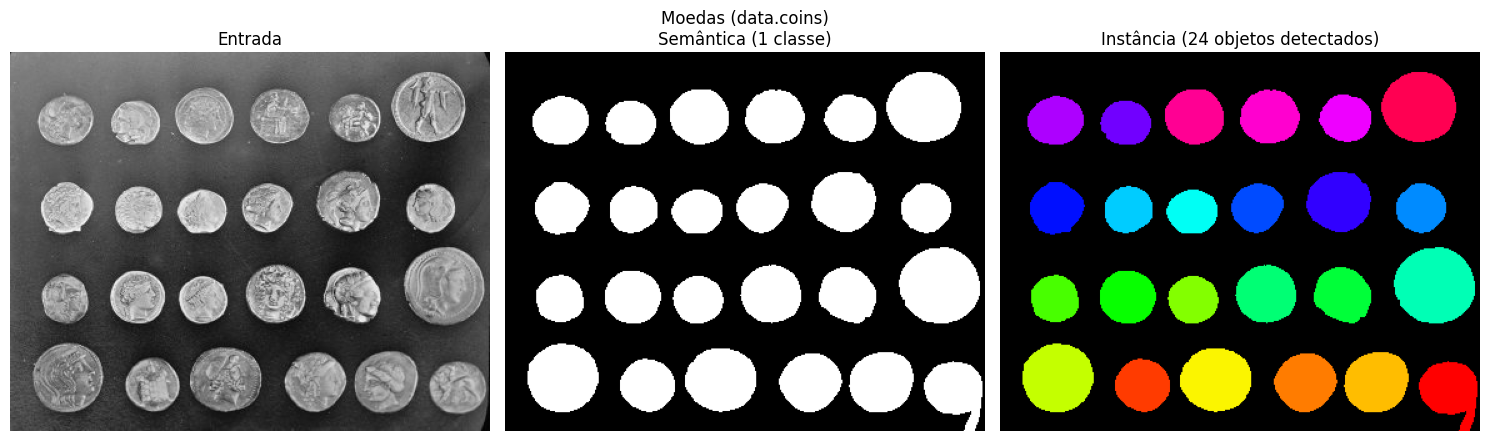

Moedas (data.coins): 24 instâncias detectadas.


In [5]:
semantica_moedas, instancias_moedas = comparar_segmentacoes(data.coins(), 'Moedas (data.coins)', area_minima=500)

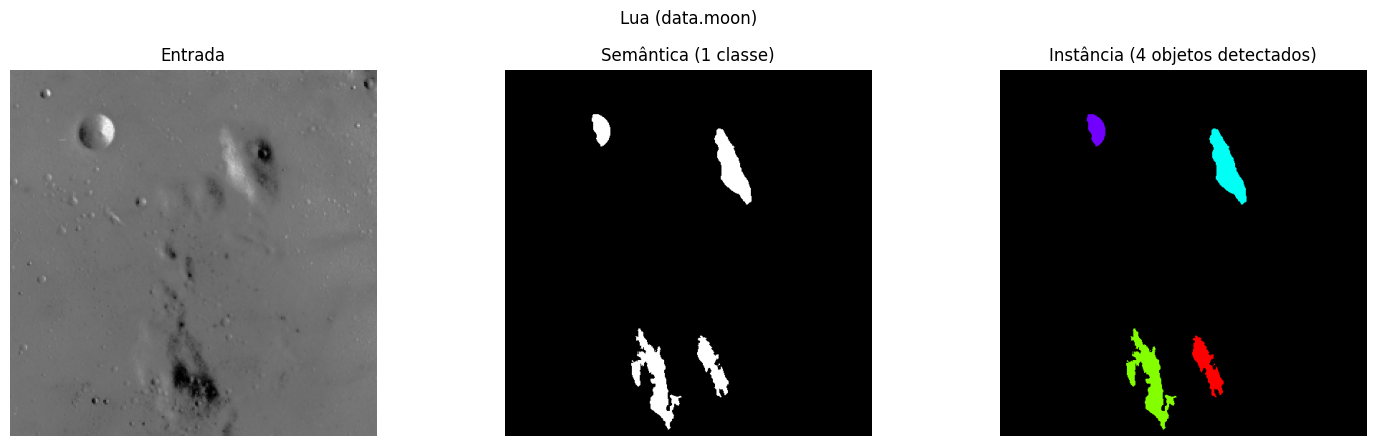

Lua (data.moon): 4 instâncias detectadas.


In [6]:
semantica_lua, instancias_lua = comparar_segmentacoes(data.moon(), 'Lua (data.moon)', area_minima=500)

# Análise dos resultados
Moedas: Como os objetos são separados e contrastam com o fundo, os contornos externos permitem distinguir várias moedas individualmente.

Lua: A imagem contém regiões de textura e luminosidade contínuas, não objetos circulares bem isolados. O mesmo limiar pode dividir regiões de iluminação em várias instâncias artificiais ou deixar de separar estruturas reais. Portanto, o resultado é menos adequado para segmentação por instância do que o das moedas.